# LSST-64: Generate a monthly representative cloud database

This notebook demonstrates the pipe-and-filter API implemented for [LSST-64](lsst-64.md). It reads historical CTIO cloud records, inspects monthly state and transition statistics, generates clouds for which **each individual month** meets the historical statistical tolerances, plots diagnostics, and writes a `rubin_scheduler`-compatible SQLite database. It does not run a scheduler simulation.

Run the cells in order with a Python kernel from an environment containing the LSST-64 implementation of `rubin_sim`, its dependencies (including `rubin_scheduler`), and Jupyter. In this multi-repository workspace, select the shared `.venv` kernel after activating that environment. The CTIO text file is supplied separately in `rubin_sim_notebooks/clouds`; on USDF or a standalone installation, set its path in the configuration cell.

The default is one simulated year to keep the interactive example short. Set `num_years = 20` for the reference-baseline use case. Historical ingestion computes twilight times for every night and can take a few minutes; longer generation runs also take more time.

In [1]:
from contextlib import closing
from pathlib import Path
import sqlite3
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from rubin_sim.clouds import (
    compute_stochastic_matrix,
    compute_transition_matrix,
    count_cloud_states,
    generate_average_clouds,
    make_cloud_figure,
    observability_acf,
    plot_cloud_histogram,
    plot_transition_histograms,
    read_historical_clouds,
    save_clouds,
)

## 1. Configure input, output, and reproducibility

The configuration discovers the example historical file when launched from anywhere inside the multi-repository workspace. Replace `historical_paths` with one or more explicit paths elsewhere. Multiple input files are combined, keeping the first occurrence of a duplicate night. Each file must have whitespace-separated columns `sday eday month year q1 q2 q3 q4`, and the combined data must have valid quarters for all twelve months.

Outputs go into `lsst-64-output` under the kernel's current working directory by default. Re-running the save cells replaces the database's `Cloud` table and the diagnostic images.

In [2]:
example_relative_path = Path(
    'rubin_sim_notebooks/clouds/clouds_1975-01-01_to_2022-09-04.txt'
)
working_directory = Path.cwd().resolve()
example_path = next(
    (root / example_relative_path
     for root in (working_directory, *working_directory.parents)
     if (root / example_relative_path).is_file()),
    working_directory / example_relative_path,
)
historical_paths = [example_path]  # Replace with your CTIO record file(s).
output_directory = working_directory / 'lsst-64-output'
output_database = output_directory / 'average_clouds.db'
num_years = 20
seed = 6563
max_retries = 10000
max_steps = 100

for path in historical_paths:
    if not path.is_file():
        raise FileNotFoundError(f'Set historical_paths to readable CTIO records: {path}')
output_directory.mkdir(parents=True, exist_ok=True)
display({'historical_paths': historical_paths, 'output_database': output_database,
         'num_years': num_years, 'seed': seed})

{'historical_paths': [PosixPath('/media/psf/aisandbox/rubin_scheduler_stuff/rubin_sim_notebooks/clouds/clouds_1975-01-01_to_2022-09-04.txt')],
 'output_database': PosixPath('/media/psf/aisandbox/rubin_scheduler_stuff/rubin_sim/docs/issues/lsst-64-output/average_clouds.db'),
 'num_years': 20,
 'seed': 6563}

## 2. Read and inspect the historical quarters

`read_historical_clouds` returns a `Clouds` DataFrame with a sorted `(year, month, sday, quarter)` index. These dates describe the **local date on which the night began**; quarters range from 1 through 4. Columns are `eighths`, fractional `cloud`, and `c_date`. Missing values (`-1` or `9` in the input) become `eighths = 9` and `cloud = NaN`.

`c_date` is the quarter-center time in integer seconds since **1975-01-01 00:00:00 TAI**. Centers divide the night between geometric 12-degree evening and morning twilight at Cerro Pachon into four equal intervals.

In [3]:
started = perf_counter()
historical_clouds = read_historical_clouds(historical_paths)
print(f'Read {len(historical_clouds):,} quarters in {perf_counter() - started:.1f} seconds')
display(historical_clouds.head(12))
display(historical_clouds.dtypes)
historical_summary = historical_clouds.groupby(level='month').agg(
    quarters=('eighths', 'size'),
    valid_quarters=('cloud', 'count'),
    mean_cloud=('cloud', 'mean'),
)
historical_summary['missing_quarters'] = (
    historical_summary.quarters - historical_summary.valid_quarters
)
display(historical_summary)

Read 69,652 quarters in 49.8 seconds


eighths  cloud  c_date
year month sday quarter                        
1975 1     1    1              0  0.000   92916
                2              0  0.000  100051
                3              0  0.000  107185
                4              0  0.000  114320
           2    1              0  0.000  179330
                2              2  0.250  186474
                3              3  0.375  193618
                4              4  0.500  200763
           3    1              0  0.000  265742
                2              3  0.375  272897
                3              4  0.500  280052
                4              0  0.000  287207

eighths      uint8
cloud      float64
c_date      uint64
dtype: object

,quarters,valid_quarters,mean_cloud,missing_quarters
month,,,,
1,5948,5690,0.078273,258
2,5424,5114,0.066362,310
3,5952,5788,0.102691,164
4,5760,5572,0.207713,188
5,5952,5623,0.362462,329
6,5760,5396,0.367494,364
7,5952,5554,0.363117,398
8,5952,5736,0.310648,216
9,5656,5373,0.280546,283


## 3. Count cloud states by month

`count_cloud_states` pools all historical years for each calendar month, excluding missing values. Its `CloudDistribution` table contains quarter counts for cloud states 0 through 8. Normalizing each row gives the target state fractions for every simulated instance of that month.

In [4]:
historical_distribution = count_cloud_states(historical_clouds)
historical_fractions = historical_distribution.div(historical_distribution.sum(axis=1), axis=0)
display(historical_distribution)
display(historical_fractions)

eighths,0,1,2,3,4,5,6,7,8
month,,,,,,,,,
1,4446,422,253,188,145,92,45,31,68
2,4156,377,178,112,86,67,51,35,52
3,4413,401,252,170,151,75,94,59,173
4,3376,501,352,215,188,137,138,176,489
5,2227,572,448,310,289,236,240,277,1024
6,2088,551,399,374,261,227,256,242,998
7,2415,436,371,285,275,160,260,175,1177
8,2819,500,372,273,220,175,198,183,996
9,2694,520,382,298,222,164,185,201,707


eighths,0,1,2,3,4,5,6,7,8
month,,,,,,,,,
1,0.781371,0.074165,0.044464,0.033040,0.025483,0.016169,0.007909,0.005448,0.011951
2,0.812671,0.073719,0.034806,0.021901,0.016817,0.013101,0.009973,0.006844,0.010168
3,0.762440,0.069281,0.043538,0.029371,0.026088,0.012958,0.016240,0.010194,0.029889
4,0.605887,0.089914,0.063173,0.038586,0.033740,0.024587,0.024767,0.031587,0.087760
5,0.396052,0.101725,0.079673,0.055131,0.051396,0.041970,0.042682,0.049262,0.182109
6,0.386953,0.102113,0.073944,0.069311,0.048369,0.042068,0.047443,0.044848,0.184952
7,0.434822,0.078502,0.066799,0.051314,0.049514,0.028808,0.046813,0.031509,0.211919
8,0.491457,0.087169,0.064854,0.047594,0.038354,0.030509,0.034519,0.031904,0.173640
9,0.501396,0.096780,0.071096,0.055462,0.041318,0.030523,0.034431,0.037409,0.131584


## 4. Inspect transition counts and empirical probabilities

`compute_transition_matrix` returns counts indexed by `(month, origin)`, with destination states 0 through 8 as columns. A pair belongs to the month of its **second quarter's starting night**. This includes transitions between consecutive nights and across month boundaries, but excludes pairs separated by missing quarters or calendar gaps. With no `prior_state`, there is no transition into the first quarter.

`compute_stochastic_matrix` divides each origin row by its total to give conditional destination probabilities. An origin with no observed outgoing pairs borrows the first supported origin in the documented fallback order. This table is useful for exploration; the generator itself takes the **raw transition counts and state counts**, not this probability table, to enforce both monthly tolerances.

In [5]:
historical_transition_matrix = compute_transition_matrix(historical_clouds)
historical_stochastic_matrix = compute_stochastic_matrix(historical_transition_matrix)
inspection_month = 10  # October; change to any month 1 through 12.
display(historical_transition_matrix.loc[inspection_month])
display(historical_stochastic_matrix.loc[inspection_month])
np.testing.assert_allclose(historical_stochastic_matrix.sum(axis=1), 1.0)
display(historical_transition_matrix.sum(axis=1).unstack('origin').rename_axis(columns='origin'))

destination,0,1,2,3,4,5,6,7,8
origin,,,,,,,,,
0,2624,199,87,30,25,15,16,11,30
1,210,249,98,35,21,13,11,5,9
2,75,100,101,59,36,22,10,7,13
3,34,41,42,63,50,16,16,8,6
4,18,25,39,33,47,30,20,10,17
5,13,10,19,21,15,31,34,16,13
6,16,11,16,10,22,16,44,28,24
7,14,6,9,12,6,13,12,40,28
8,36,15,10,13,18,14,24,12,342


destination,0,1,2,3,4,5,6,7,8
origin,,,,,,,,,
0,0.864011,0.065525,0.028647,0.009878,0.008232,0.004939,0.005268,0.003622,0.009878
1,0.322581,0.382488,0.150538,0.053763,0.032258,0.019969,0.016897,0.007680,0.013825
2,0.177305,0.236407,0.238771,0.139480,0.085106,0.052009,0.023641,0.016548,0.030733
3,0.123188,0.148551,0.152174,0.228261,0.181159,0.057971,0.057971,0.028986,0.021739
4,0.075314,0.104603,0.163180,0.138075,0.196653,0.125523,0.083682,0.041841,0.071130
5,0.075581,0.058140,0.110465,0.122093,0.087209,0.180233,0.197674,0.093023,0.075581
6,0.085561,0.058824,0.085561,0.053476,0.117647,0.085561,0.235294,0.149733,0.128342
7,0.100000,0.042857,0.064286,0.085714,0.042857,0.092857,0.085714,0.285714,0.200000
8,0.074380,0.030992,0.020661,0.026860,0.037190,0.028926,0.049587,0.024793,0.706612


origin,0,1,2,3,4,5,6,7,8
month,,,,,,,,,
1,4420,419,251,189,144,89,44,31,67
2,4140,375,179,112,86,69,52,35,49
3,4407,402,250,169,152,75,94,58,171
4,3375,498,351,215,187,137,137,174,485
5,2233,569,447,309,287,236,239,274,1017
6,2077,550,400,372,261,226,256,246,995
7,2406,431,371,282,276,162,260,174,1168
8,2811,500,372,274,214,175,198,180,992
9,2690,523,378,300,226,159,185,199,708


## 5. Generate monthly representative clouds

The generator chains months from January 1975, preserving the final state of each month as the next month's prior state. It checks state counts within one quarter of expectation, and transition counts within `sqrt(expected)` (or one count when the expectation is below one). A shared seeded random-number generator makes the run reproducible without resetting failed attempts.

The retry and progress limits prevent unbounded sampling. A `RuntimeError` means a month could not satisfy the constraints within those limits; it is not a valid result to save. The generator may add one extra month so that `max(c_date) - min(c_date)` covers at least `num_years * 31557600` seconds, as needed by the scheduler's Julian-year wrapping.

In [6]:
started = perf_counter()
simulated_clouds = generate_average_clouds(
    historical_transition_matrix,
    historical_distribution,
    num_years,
    seed=seed,
    max_retries=max_retries,
    max_steps=max_steps,
)
print(f'Generated {len(simulated_clouds):,} quarters in {perf_counter() - started:.1f} seconds')
display(simulated_clouds.head(8))
display(simulated_clouds.tail(8))
span_seconds = int(simulated_clouds.c_date.iloc[-1]) - int(simulated_clouds.c_date.iloc[0])
assert span_seconds >= num_years * 31557600
assert simulated_clouds.eighths.between(0, 8).all()
print(f'Database span: {span_seconds / 31557600:.4f} Julian years')

Generated 29,344 quarters in 45.2 seconds


eighths  cloud  c_date
year month sday quarter                        
1975 1     1    1              0    0.0   92916
                2              0    0.0  100051
                3              0    0.0  107185
                4              0    0.0  114320
           2    1              0    0.0  179330
                2              0    0.0  186474
                3              0    0.0  193618
                4              0    0.0  200763

eighths  cloud     c_date
year month sday quarter                           
1995 1     30   1              0    0.0  633750276
                2              0    0.0  633757972
                3              0    0.0  633765669
                4              0    0.0  633773366
           31   1              0    0.0  633836645
                2              0    0.0  633844368
                3              0    0.0  633852092
                4              0    0.0  633859815

Database span: 20.0829 Julian years


## 6. Verify each simulated month, not just pooled statistics

Aggregate plots can hide an atypical individual month. Here we independently compare every `(year, month)` with its historical target. For transition counts, retain the true preceding quarter when slicing a month: only the first simulated month has no incoming transition. Expectations scale the historical **joint pair frequencies**, not the conditional stochastic rows. Floating-point comparisons allow `1e-12` numerical slack.

In [7]:
monthly_checks = []
offset = 0
for (year, month), month_clouds in simulated_clouds.groupby(level=['year', 'month'], sort=True):
    prior_state = None if offset == 0 else int(simulated_clouds.eighths.iloc[offset - 1])
    state_counts = count_cloud_states(month_clouds).loc[month].to_numpy(dtype=float)
    expected_states = len(month_clouds) * historical_fractions.loc[month].to_numpy()
    transition_counts = compute_transition_matrix(month_clouds, prior_state=prior_state)
    observed_pairs = transition_counts.loc[month].to_numpy(dtype=float)
    historical_pairs = historical_transition_matrix.loc[month].to_numpy(dtype=float)
    num_pairs = len(month_clouds) - (prior_state is None)
    expected_pairs = num_pairs * historical_pairs / historical_pairs.sum()
    tolerance = np.where(expected_pairs < 1, 1, np.sqrt(expected_pairs))
    state_error = np.abs(state_counts - expected_states)
    pair_error = np.abs(observed_pairs - expected_pairs)
    assert observed_pairs.sum() == num_pairs
    monthly_checks.append({
        'year': int(year), 'month': int(month), 'quarters': len(month_clouds),
        'transitions': num_pairs, 'max_state_count_error': state_error.max(),
        'max_transition_tolerance_ratio': (pair_error / tolerance).max(),
        'states_pass': bool(np.all(state_error <= 1 + 1e-12)),
        'transitions_pass': bool(np.all(pair_error <= tolerance + 1e-12)),
    })
    offset += len(month_clouds)
monthly_checks = pd.DataFrame(monthly_checks).set_index(['year', 'month'])
display(monthly_checks)
assert monthly_checks[['states_pass', 'transitions_pass']].to_numpy().all()

quarters  transitions  max_state_count_error  \
year month                                                 
1975 1           124          123               0.675571   
     2           112          112               0.980837   
     3           124          124               0.590878   
     4           120          120               0.950467   
     5           124          124               0.418460   
...              ...          ...                    ...   
1994 9           120          120               0.832496   
     10          124          124               0.866382   
     11          120          120               0.702630   
     12          124          124               0.497254   
1995 1           124          124               0.980668   

            max_transition_tolerance_ratio  states_pass  transitions_pass  
year month                                                                 
1975 1                            0.912982         True              True  
     2                            0.934079         True              True  
     3                            0.871236         True              True  
     4                            0.892067         True              True  
     5                            0.972376         True              True  
...                                    ...          ...               ...  
1994 9                            0.894188         True              True  
     10                           0.867356         True              True  
     11                           0.904847         True              True  
     12                           0.885883         True              True  
1995 1                            0.978069         True              True  

[241 rows x 6 columns]

## 7. Plot combined monthly diagnostics

The cloud histograms compare normalized distributions across all supplied years. Transition panels show raw counts with separate colorbar scales, since the historical sample is much longer than the simulation. Both figures are displayed inline and saved as PNGs.

destination,0,1,2,3,4,5,6,7,8
origin,,,,,,,,,
0,1157,88,40,13,12,8,9,5,19
1,91,103,40,15,11,7,5,6,8
2,34,45,42,24,14,9,6,3,7
3,16,15,17,29,22,7,9,4,4
4,9,10,17,13,20,11,10,5,8
5,8,6,10,11,6,10,11,6,7
6,9,8,7,8,5,8,17,10,12
7,8,6,5,3,2,7,4,15,10
8,17,8,8,6,11,8,11,8,137


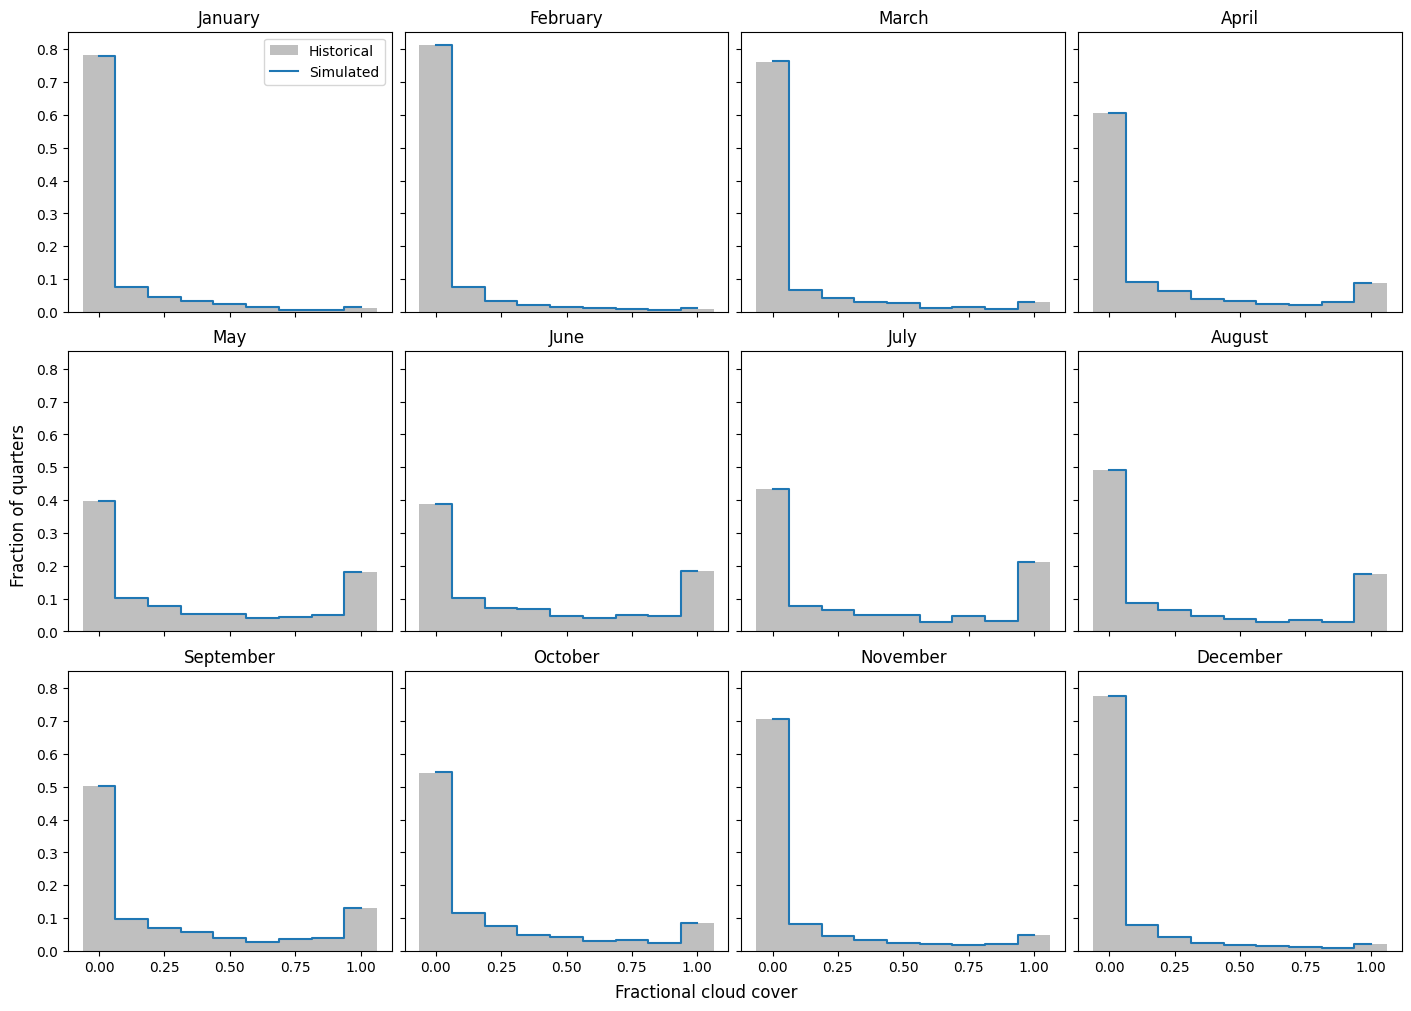

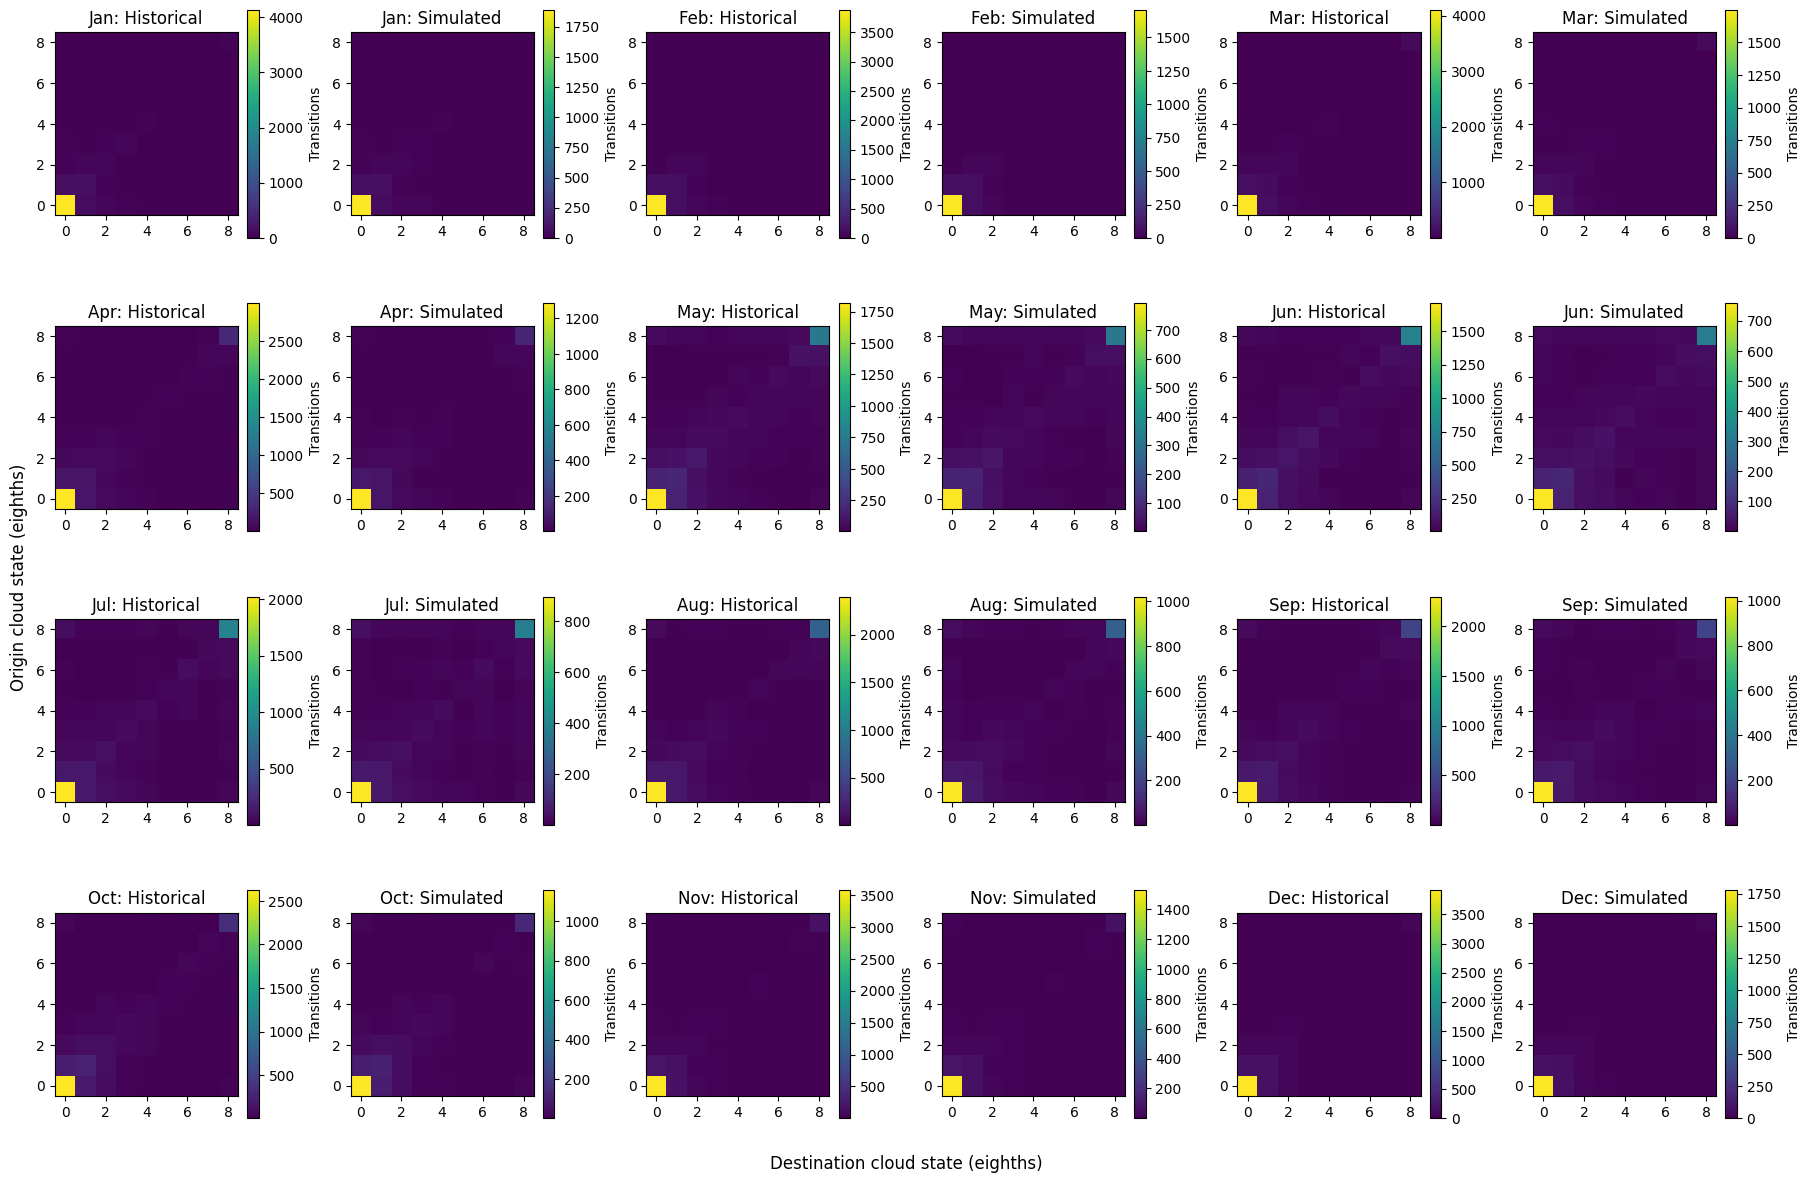

In [8]:
simulated_distribution = count_cloud_states(simulated_clouds)
simulation_transition_matrix = compute_transition_matrix(simulated_clouds)
display(simulation_transition_matrix.loc[inspection_month])

cloud_figure = plot_cloud_histogram(historical_distribution, simulated_distribution)
cloud_figure.savefig(output_directory / 'cloud_histogram.png', dpi=120)
display(cloud_figure)
plt.close(cloud_figure)

transition_figure = plot_transition_histograms(
    historical_transition_matrix, simulation_transition_matrix
)
transition_figure.savefig(output_directory / 'transition_histograms.png', dpi=120)
display(transition_figure)
plt.close(transition_figure)

### Inspect the complete simulated cloud sequence

`make_cloud_figure` shows every simulated quarter as a horizontal strip for its year, with day of year on the horizontal axis. Pass the `eighths` Series without filtering so the plot includes all generated years and any extra coverage month. Cividis maps clear skies (0 eighths) to dark colors and overcast skies (8 eighths) to yellow; missing quarters are red. The red remainder of a partial final year is outside the generated sequence, not missing records within the simulation.

The figure is displayed inline and saved as `simulated_cloud_sequence.png`.

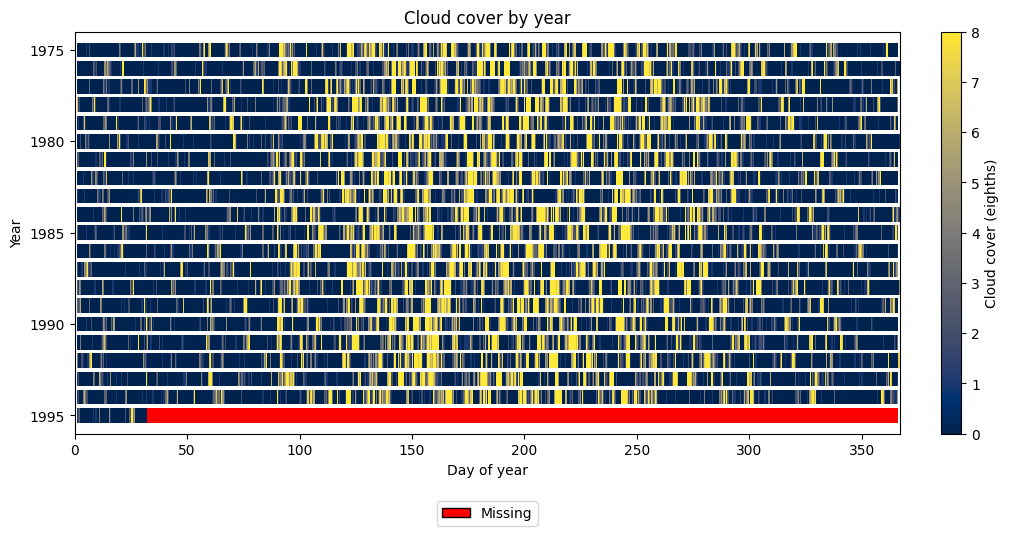

In [9]:
sequence_figure = make_cloud_figure(simulated_clouds.eighths)
sequence_figure.savefig(output_directory / 'simulated_cloud_sequence.png', dpi=120)
display(sequence_figure)
plt.close(sequence_figure)

### Inspect a selected year

Use a boolean mask to preserve all four index levels and their dtypes. When the selected year is not the first, explicitly pass the last state of the preceding year to retain the transition into January. The year-overlay histogram below uses the dictionary form of the plotting API and excludes any extra coverage year; the transition plot uses `selected_year`.

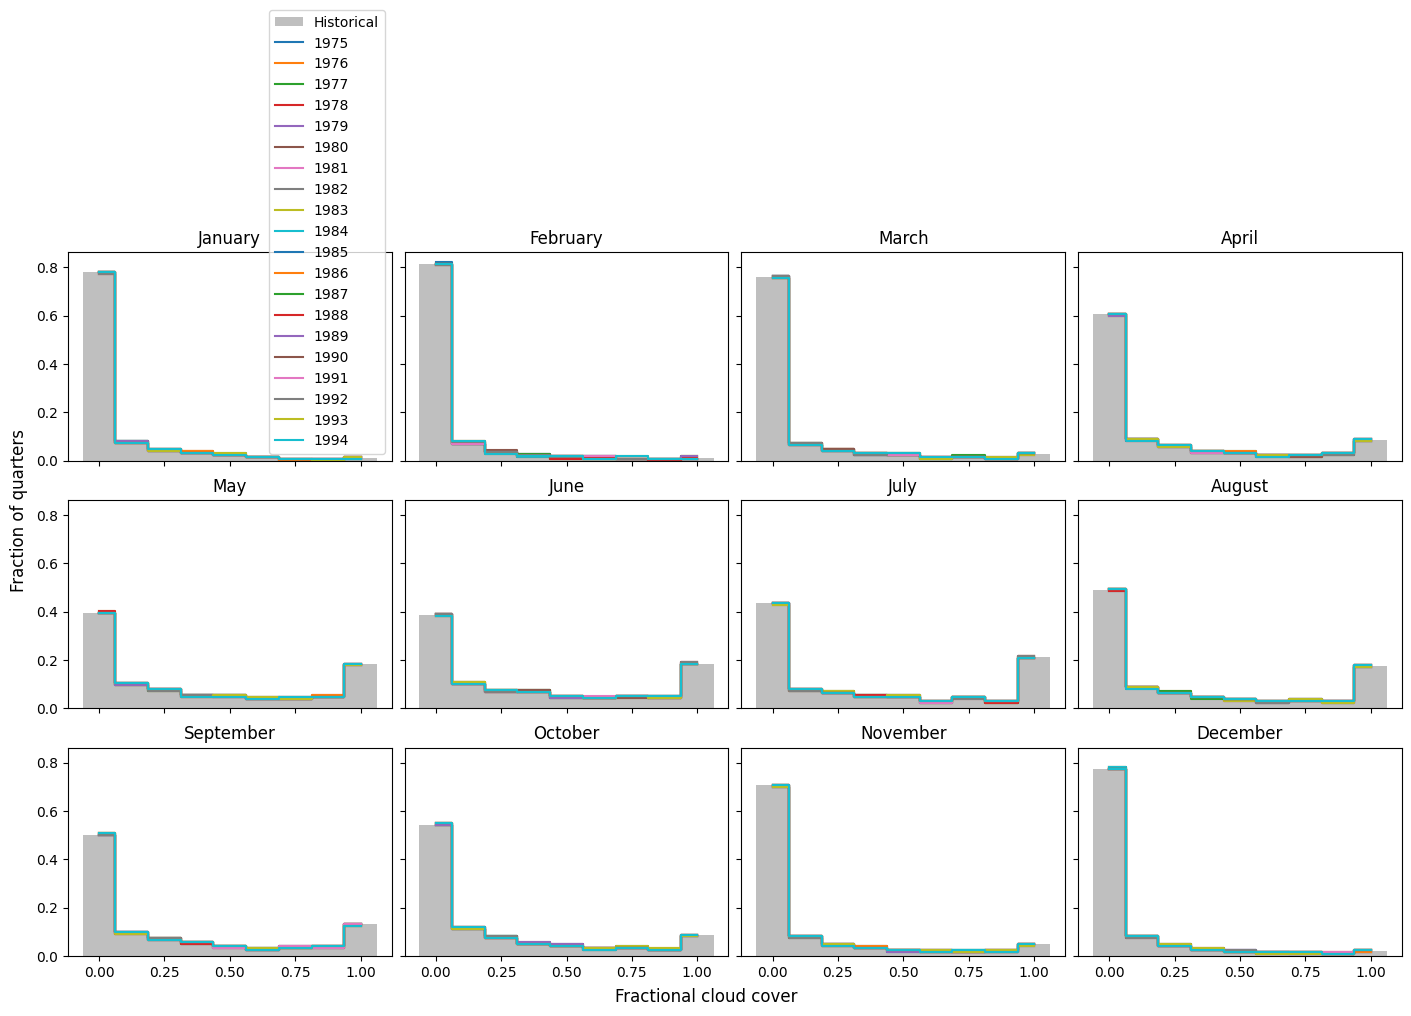

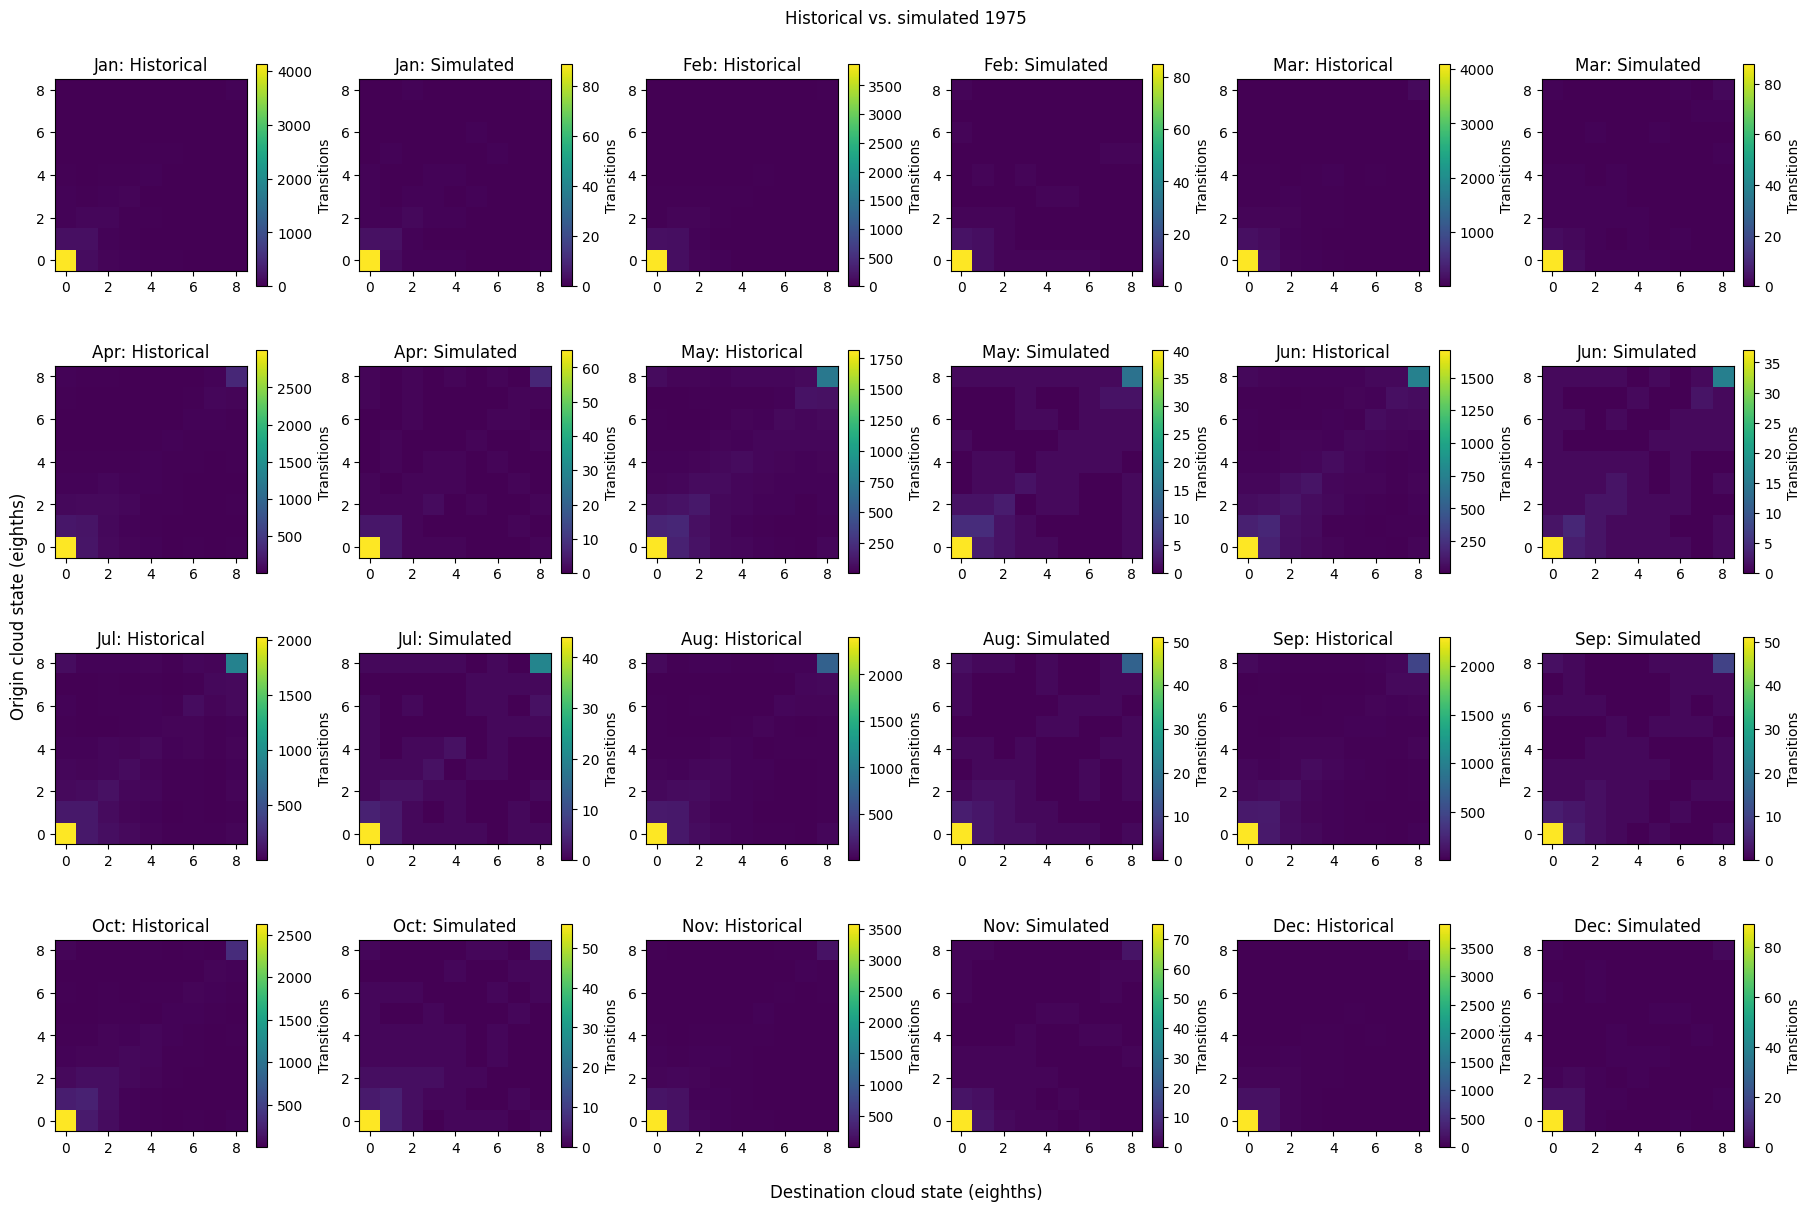

In [10]:
selected_year = 1975  # Choose a generated year, e.g. 1976 when num_years >= 2.
year_values = simulated_clouds.index.get_level_values('year')
year_clouds = simulated_clouds.loc[year_values == selected_year]
if year_clouds.empty:
    raise ValueError(f'No simulated data for selected_year={selected_year}')
first_position = simulated_clouds.index.get_loc(year_clouds.index[0])
year_prior_state = None if first_position == 0 else int(simulated_clouds.eighths.iloc[first_position - 1])
year_transition_matrix = compute_transition_matrix(year_clouds, prior_state=year_prior_state)

distributions_by_year = {
    year: count_cloud_states(simulated_clouds.loc[year_values == year])
    for year in range(1975, 1975 + num_years)
}
year_cloud_figure = plot_cloud_histogram(historical_distribution, distributions_by_year)
display(year_cloud_figure)
plt.close(year_cloud_figure)
year_transition_figure = plot_transition_histograms(
    historical_transition_matrix, year_transition_matrix
)
year_transition_figure.suptitle(f'Historical vs. simulated {selected_year}')
display(year_transition_figure)
plt.close(year_transition_figure)

## 8. Save and inspect the scheduler database

`save_clouds(path, clouds)` writes `Cloud(cloudId INTEGER PRIMARY KEY, c_date INTEGER, cloud DOUBLE, source TEXT)`. IDs start at one, `cloud` is fractional cover in multiples of 1/8, and `source` is always `simulation`. The existing `Cloud` table is replaced transactionally; other tables are preserved. The following read-only queries inspect the result and verify its row count, duration, and values.

In [11]:
save_clouds(output_database, simulated_clouds)
with closing(sqlite3.connect(f'{output_database.resolve().as_uri()}?mode=ro', uri=True)) as connection:
    display(pd.read_sql_query('PRAGMA table_info(Cloud)', connection))
    display(pd.read_sql_query('SELECT * FROM Cloud ORDER BY cloudId LIMIT 8', connection))
    database_summary = pd.read_sql_query(
        'SELECT COUNT(*) AS quarters, MIN(c_date) AS first_second, '
        'MAX(c_date) AS last_second, MIN(cloud) AS min_cloud, '
        'MAX(cloud) AS max_cloud FROM Cloud', connection,
    )
    invalid_rows = connection.execute(
        "SELECT COUNT(*) FROM Cloud WHERE cloud IS NULL OR cloud < 0 OR cloud > 1 "
        "OR cloud * 8 != CAST(cloud * 8 AS INTEGER) OR source IS NOT 'simulation'"
    ).fetchone()[0]
display(database_summary)
assert int(database_summary.quarters.iloc[0]) == len(simulated_clouds)
assert int(database_summary.last_second.iloc[0]) - int(database_summary.first_second.iloc[0]) == span_seconds
assert invalid_rows == 0
print(f'Saved database: {output_database.resolve()}')

,cid,name,type,notnull,dflt_value,pk
0,0,cloudId,INTEGER,0,None,1
1,1,c_date,INTEGER,0,None,0
2,2,cloud,DOUBLE,0,None,0
3,3,source,TEXT,0,None,0


,cloudId,c_date,cloud,source
0,1,92916,0.0,simulation
1,2,100051,0.0,simulation
2,3,107185,0.0,simulation
3,4,114320,0.0,simulation
4,5,179330,0.0,simulation
5,6,186474,0.0,simulation
6,7,193618,0.0,simulation
7,8,200763,0.0,simulation


,quarters,first_second,last_second,min_cloud,max_cloud
0,29344,92916,633859815,0.0,1.0


Saved database: /media/psf/aisandbox/rubin_scheduler_stuff/rubin_sim/docs/issues/lsst-64-output/average_clouds.db


## Alternative: Run the same pipeline without intermediate inspection

The cells above retain every intermediate product for interactive exploration. For batch use, `cloud_generation_workflow` performs ingestion, statistics, generation, saving, and optional diagnostics in one call. It returns the generated `Clouds` DataFrame. The example below is deliberately not an executable cell, to avoid generating the database twice.

```python
from rubin_sim.clouds import cloud_generation_workflow

simulated_clouds = cloud_generation_workflow(
    historical_paths,
    output_database,
    num_years=num_years,
    seed=seed,
    max_retries=max_retries,
    max_steps=max_steps,
    cloud_histogram=output_directory / 'cloud_histogram.png',
    transition_histograms=output_directory / 'transition_histograms.png',
)
```

The equivalent shell interface, using explicit paths and an existing output directory, is:

```bash
python -m rubin_sim.clouds /path/to/clouds_1975-01-01_to_2022-09-04.txt \
    --output-database /path/to/lsst-64-output/average_clouds.db \
    --num-years 1 --seed 6563 --max-retries 10000 --max-steps 100 \
    --cloud-histogram /path/to/lsst-64-output/cloud_histogram.png \
    --transition-histograms /path/to/lsst-64-output/transition_histograms.png \
    --cloud-figure /path/to/lsst-64-output/simulated_cloud_sequence.png
```

## Optional: Compare observability autocorrelation

These two examples compare the historical ACF for `inspection_month` with the simulation pooled across all years and with just `selected_year`. Set `num_years >= 2` above to make the pooled and individual-year comparisons distinct for October. Observability is 1 when fractional cloud cover is strictly below `cloud_threshold`, and 0 otherwise; cover equal to the threshold is not observable. Lags are measured in quarter nights, so a lag of 4 corresponds to one night.

Pass the full cloud frames: the API masks out-of-month quarters and missing data with NaN, preserving calendar spacing instead of joining separate years' months. `missing='conservative'` determines how statsmodels handles these gaps. The ACF is an exploratory diagnostic, not an additional generation tolerance. A selection with too little data or constant observability raises `ValueError`; choose another threshold or month in that case.

The plots require the optional `statsmodels` package to be importable in the current kernel. If it is unavailable, this cell prints a skip message without affecting the other diagnostics. Figures are displayed inline and saved as PNGs. ACF plotting is API-only, so there is no corresponding CLI option.

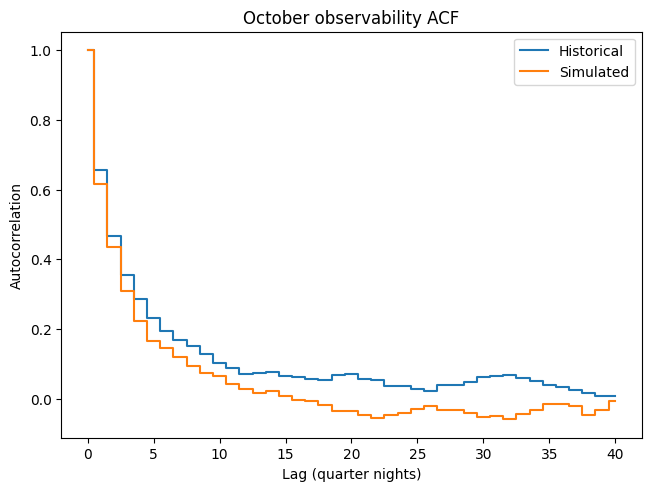

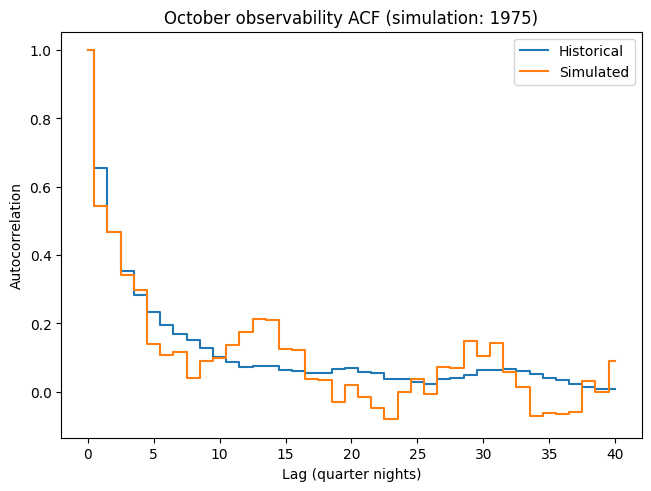

In [12]:
cloud_threshold = 2.5/8
acf_nlags = 40  # Ten nights of quarter-night lags.

try:
    from statsmodels.tsa.stattools import acf
except ImportError:
    print('Skipping ACF plots: statsmodels must be importable in the current kernel.')
else:
    for acf_year, label in [(None, 'all_years'), (selected_year, str(selected_year))]:
        acf_figure = observability_acf(
            cloud_threshold,
            historical_clouds,
            simulated_clouds,
            month=inspection_month,
            year=acf_year,
            nlags=acf_nlags,
            missing='conservative',
        )
        for line in acf_figure.axes[0].lines:
            line.set_drawstyle("steps-mid")

        acf_figure.savefig(
            output_directory / f'observability_acf_month_{inspection_month:02d}_{label}.png',
            dpi=120,
        )
        display(acf_figure)
        plt.close(acf_figure)

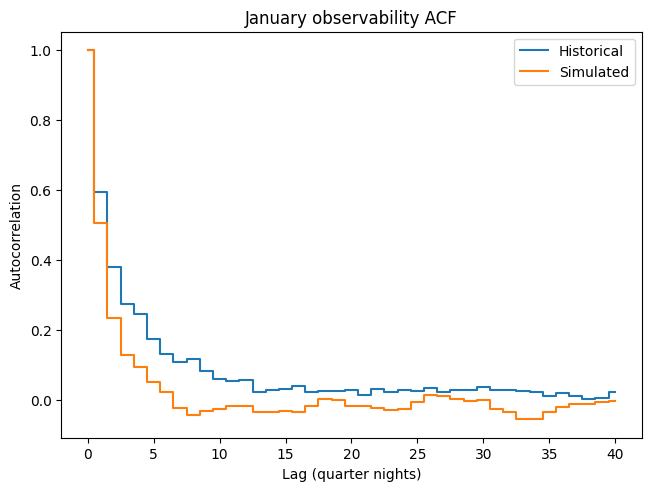

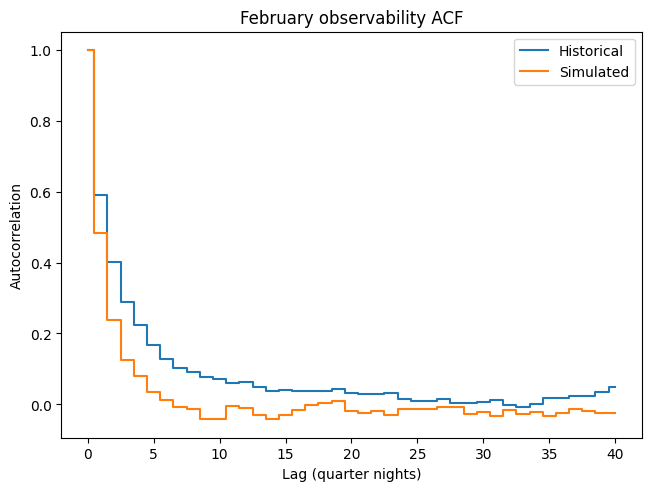

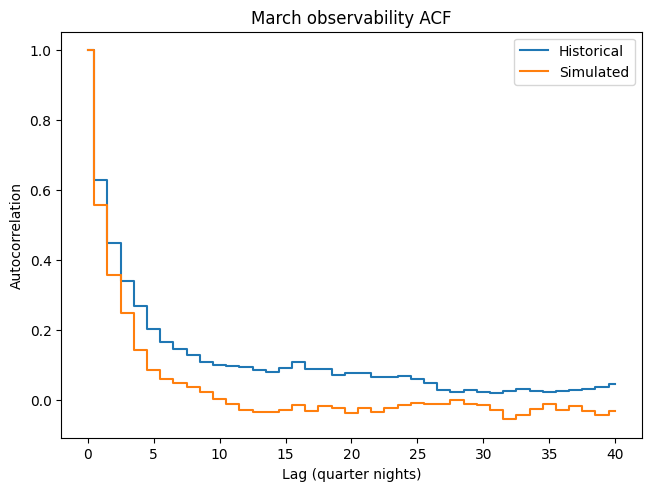

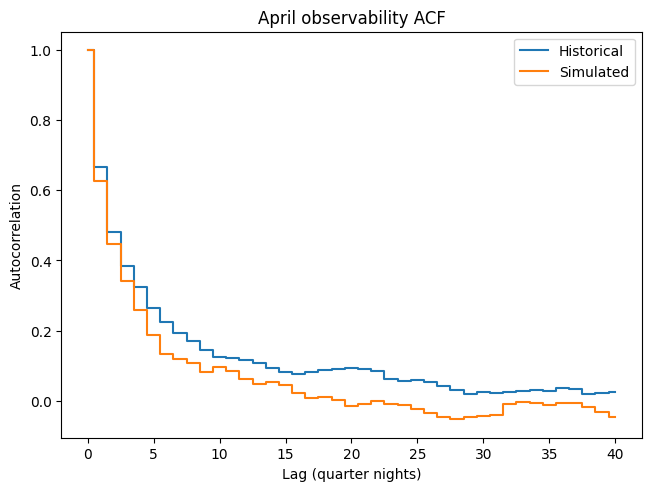

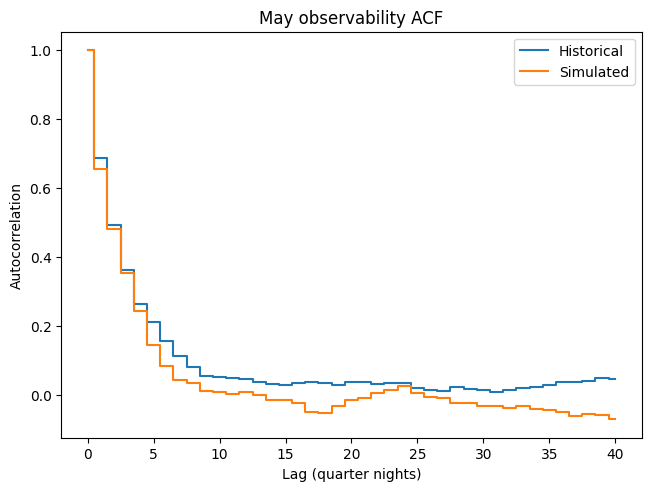

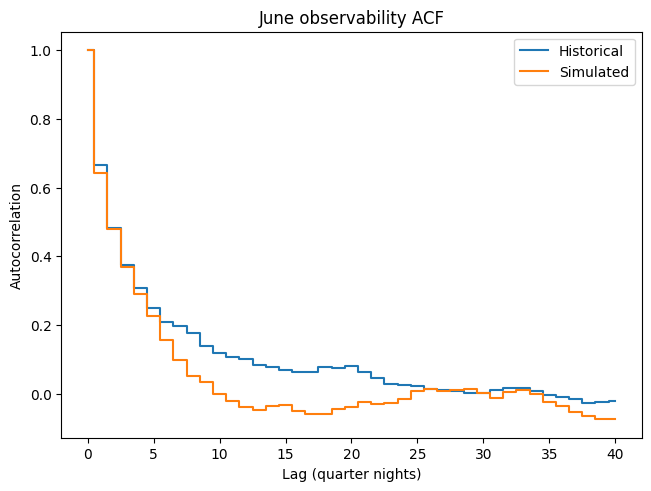

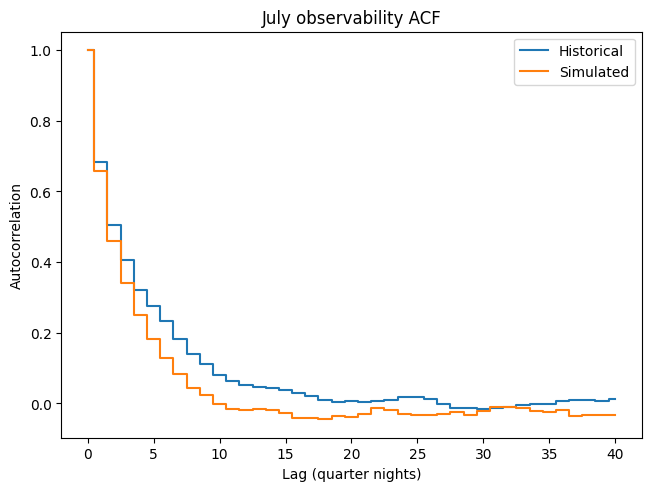

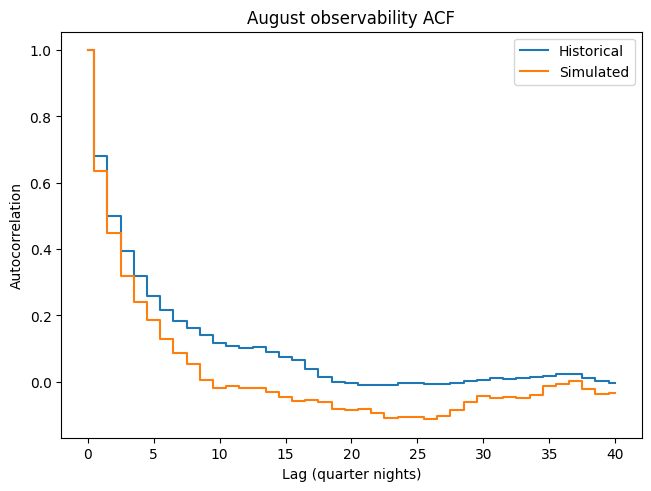

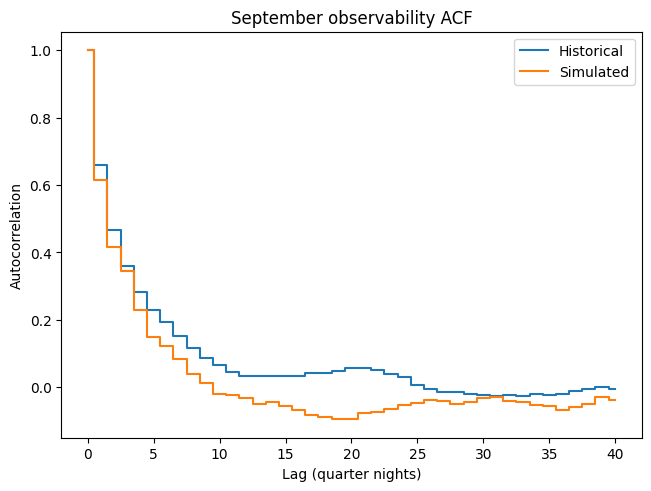

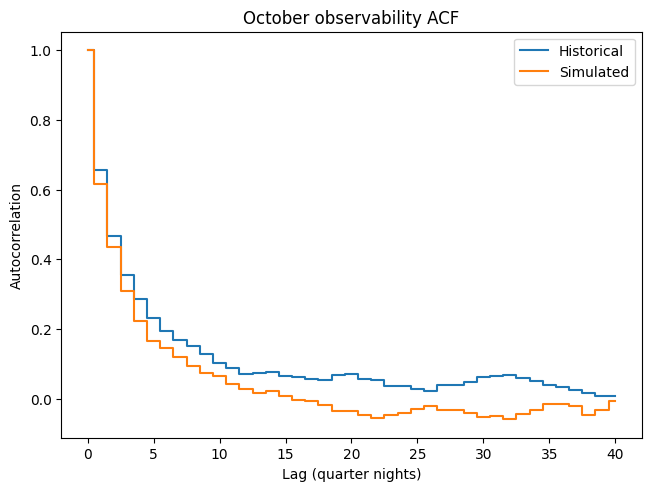

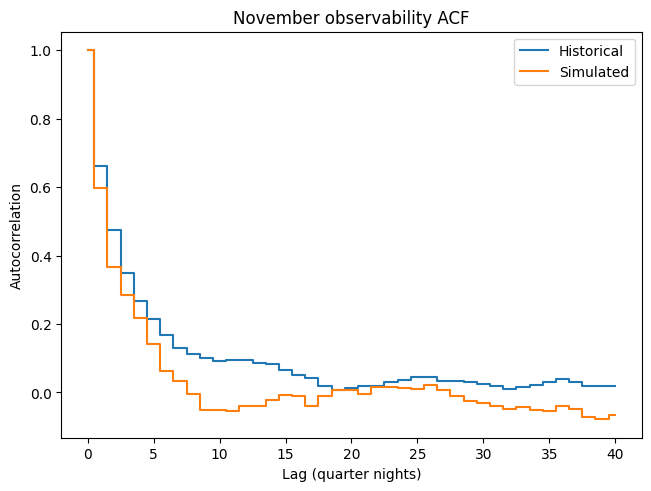

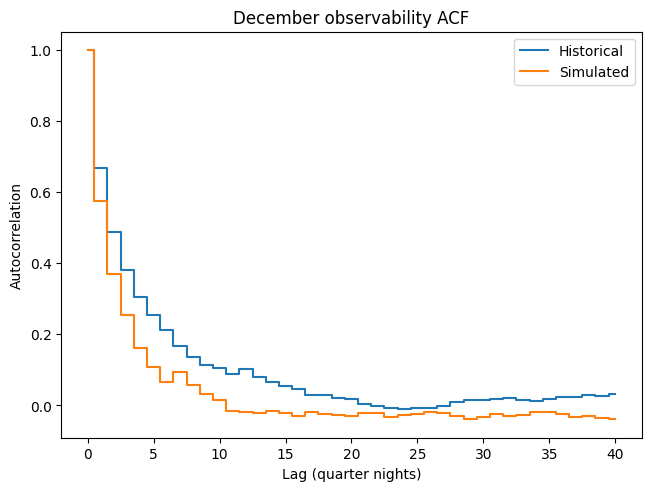

In [13]:
cloud_threshold = 2.5/8
acf_nlags = 40  # Ten nights of quarter-night lags.

try:
    from statsmodels.tsa.stattools import acf
except ImportError:
    print('Skipping ACF plots: statsmodels must be importable in the current kernel.')
else:
    acf_year = None
    label = 'all_years'
    for inspection_month in np.arange(1, 13):
        acf_figure = observability_acf(
            cloud_threshold,
            historical_clouds,
            simulated_clouds,
            month=inspection_month,
            year=acf_year,
            nlags=acf_nlags,
            missing='conservative',
        )
        for line in acf_figure.axes[0].lines:
            line.set_drawstyle("steps-mid")

        acf_figure.savefig(
            output_directory / f'observability_acf_month_{inspection_month:02d}_{label}.png',
            dpi=120,
        )
        display(acf_figure)
        plt.close(acf_figure)